--- Step 1: Checking Google Drive Connection ---
Mounted at /content/drive

--- Step 2: Scanning Raw Dataset ---
📁 Anthracnose: 295 images
📁 Black Pox: 374 images
📁 Black Rot: 542 images
📁 Blotch: 36 images
📁 Healthy: 1424 images
📁 Powdery Mildew: 417 images
📁 Scab: 23 images

✅ High-Resolution chart saved successfully to: /content/drive/MyDrive/Green_Apple/dataset/outputs/raw_dataset_distribution.png


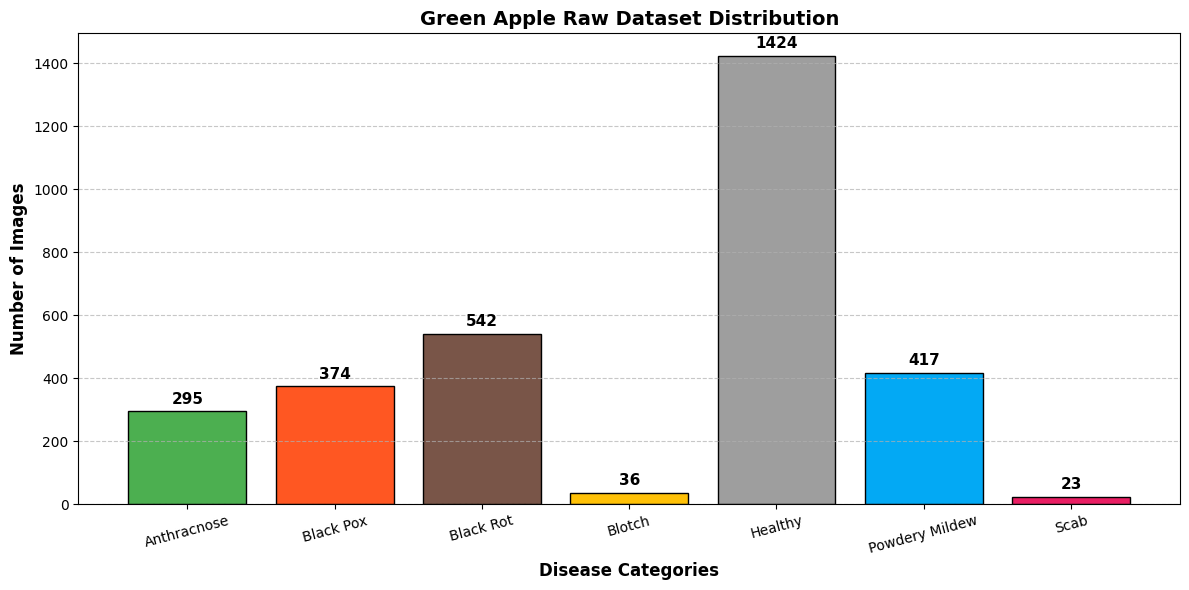

In [ ]:
# Cell 1: Environment Setup, Distribution, & Artifact Logging
import os
import matplotlib.pyplot as plt
from google.colab import drive

print("--- Step 1: Checking Google Drive Connection ---")
# Using force_remount prevents the "already contains files" crash
drive.mount('/content/drive', force_remount=True)

print("\n--- Step 2: Scanning Raw Dataset ---")
# Paths based on your updated folder structure
dataset_path = '/content/drive/MyDrive/Green_Apple/dataset/raw'
output_path = '/content/drive/MyDrive/Green_Apple/dataset/outputs'

# Ensure the output directory exists so it doesn't crash when saving
os.makedirs(output_path, exist_ok=True)

categories = []
counts = []

# Check if path exists to avoid errors
if os.path.exists(dataset_path):
    # Sort the folders so they appear in alphabetical order
    for folder in sorted(os.listdir(dataset_path)):
        folder_path = os.path.join(dataset_path, folder)

        # Ensure we are looking at folders only
        if os.path.isdir(folder_path):
            # Count only files (images), ignoring hidden files
            num_images = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])

            categories.append(folder)
            counts.append(num_images)
            print(f"📁 {folder}: {num_images} images")
else:
    print(f"❌ Error: The path '{dataset_path}' was not found. Please check your Drive folder structure.")

# Step 3: Visualizing and Logging the Data Artifact
if counts:
    plt.figure(figsize=(12, 6))

    # Expanded color palette to accommodate the 7 categories
    bar_colors = ['#4CAF50', '#FF5722', '#795548', '#FFC107', '#9E9E9E', '#03A9F4', '#E91E63']
    bars = plt.bar(categories, counts, color=bar_colors[:len(categories)], edgecolor='black')

    # Add numbers on top of bars dynamically
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + (max(counts)*0.01), int(yval),
                 ha='center', va='bottom', fontweight='bold', fontsize=11)

    plt.xlabel('Disease Categories', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Green Apple Raw Dataset Distribution', fontsize=14, fontweight='bold')
    plt.xticks(rotation=15)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()

    # ---------------------------------------------------------
    # PROFESSIONAL ARTIFACT LOGGING
    # Must run BEFORE plt.show() otherwise the image saves blank
    # ---------------------------------------------------------
    save_file = os.path.join(output_path, 'raw_dataset_distribution.png')
    plt.savefig(save_file, dpi=300, bbox_inches='tight')
    print(f"\n✅ High-Resolution chart saved successfully to: {save_file}")

    # Display in Colab
    plt.show()

In [ ]:
# Cell 2: Data Standardization (The Renaming Script)
import os

print("--- Starting Data Standardization & Renaming ---")

# Updated path to point exactly to your new 'raw' folder
DATASET_PATH = '/content/drive/MyDrive/Green_Apple/dataset/raw'

if os.path.exists(DATASET_PATH):
    # Find all subdirectories, strictly ignoring hidden system folders
    categories = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d)) and not d.startswith('.')])

    print(f"Found {len(categories)} categories: {categories}\n")

    for category in categories:
        category_path = os.path.join(DATASET_PATH, category)

        # Grab all valid files, strictly ignoring hidden Colab/Drive files
        files = [f for f in os.listdir(category_path) if os.path.isfile(os.path.join(category_path, f)) and not f.startswith('.')]

        # Sort files to maintain order
        files.sort()

        # Create a clean, lowercase name (e.g., "Black Pox" -> "black_pox")
        clean_category_name = category.lower().replace(" ", "_")

        print(f"Processing '{category}' -> Renaming {len(files)} files to '{clean_category_name}_000X.jpg'...")

        # Step 2.1: Rename to temporary names to avoid overwrite collisions
        temp_files = []
        for i, filename in enumerate(files):
            old_filepath = os.path.join(category_path, filename)
            _, ext = os.path.splitext(filename)

            # Force extension to lowercase, default to .jpg if missing
            if not ext: ext = '.jpg'

            temp_filename = f"temp_{clean_category_name}_{i}{ext.lower()}"
            temp_filepath = os.path.join(category_path, temp_filename)

            os.rename(old_filepath, temp_filepath)
            temp_files.append(temp_filename)

        # Step 2.2: Rename from temporary names to final standardized names
        count = 1
        for temp_filename in temp_files:
            temp_filepath = os.path.join(category_path, temp_filename)
            _, ext = os.path.splitext(temp_filename)

            # Final Format Example: black_pox_0001.jpg
            final_filename = f"{clean_category_name}_{count:04d}{ext.lower()}"
            final_filepath = os.path.join(category_path, final_filename)

            os.rename(temp_filepath, final_filepath)
            count += 1

    print("\n✅ Standardization Complete! All 7 folders are now perfectly organized.")
else:
    print(f"❌ Error: Could not find '{DATASET_PATH}'. Please check your Drive connection.")

--- Starting Data Standardization & Renaming ---
Found 7 categories: ['Anthracnose', 'Black Pox', 'Black Rot', 'Blotch', 'Healthy', 'Powdery Mildew', 'Scab']

Processing 'Anthracnose' -> Renaming 295 files to 'anthracnose_000X.jpg'...
Processing 'Black Pox' -> Renaming 374 files to 'black_pox_000X.jpg'...
Processing 'Black Rot' -> Renaming 542 files to 'black_rot_000X.jpg'...
Processing 'Blotch' -> Renaming 36 files to 'blotch_000X.jpg'...
Processing 'Healthy' -> Renaming 1424 files to 'healthy_000X.jpg'...
Processing 'Powdery Mildew' -> Renaming 417 files to 'powdery_mildew_000X.jpg'...
Processing 'Scab' -> Renaming 23 files to 'scab_000X.jpg'...

✅ Standardization Complete! All 7 folders are now perfectly organized.


In [ ]:
# Cell 3: The "Poison" Check & Color Normalization
import os
from PIL import Image, UnidentifiedImageError

print("--- Starting Poison Check & Color Normalization ---")

# Explicitly defining the path to match your new structure
DATASET_PATH = '/content/drive/MyDrive/Green_Apple/dataset/raw'

if os.path.exists(DATASET_PATH):
    corrupted_count = 0
    converted_count = 0

    # Find all subdirectories, strictly ignoring hidden Colab/Drive folders
    categories = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d)) and not d.startswith('.')])

    for category in categories:
        category_path = os.path.join(DATASET_PATH, category)

        # Grab all valid files, strictly ignoring hidden system files
        files = [f for f in os.listdir(category_path) if os.path.isfile(os.path.join(category_path, f)) and not f.startswith('.')]

        print(f"Scanning '{category}' ({len(files)} images)...")

        for filename in files:
            filepath = os.path.join(category_path, filename)

            try:
                # Open the image using Pillow
                with Image.open(filepath) as img:
                    # Force load the image data to catch deeper binary file corruption
                    img.load()

                    # Check color mode. Lite-HRNet requires exactly 3 channels (RGB)
                    # If it's RGBA (transparent) or Grayscale (L), convert it.
                    if img.mode != 'RGB':
                        rgb_img = img.convert('RGB')
                        # Save it back, overwriting the old non-RGB file
                        rgb_img.save(filepath, format='JPEG')
                        converted_count += 1

            except (IOError, SyntaxError, UnidentifiedImageError) as e:
                # If the file is mathematically broken, delete it permanently
                print(f"  [WARNING] Corrupted file detected and removed: {filename}")
                os.remove(filepath)
                corrupted_count += 1

    print("\n✅ Poison Check & Normalization Complete!")
    print(f"🛠️ Files converted to strict RGB: {converted_count}")
    print(f"🗑️ Corrupted files automatically removed: {corrupted_count}")
else:
    print(f"❌ Error: Could not find '{DATASET_PATH}'. Please verify your Drive connection.")

--- Starting Poison Check & Color Normalization ---
Scanning 'Anthracnose' (295 images)...
Scanning 'Black Pox' (374 images)...
Scanning 'Black Rot' (542 images)...
Scanning 'Blotch' (36 images)...
Scanning 'Healthy' (1424 images)...
Scanning 'Powdery Mildew' (417 images)...
Scanning 'Scab' (23 images)...

✅ Poison Check & Normalization Complete!
🛠️ Files converted to strict RGB: 0
🗑️ Corrupted files automatically removed: 0


--- Starting EDA on Image Dimensions ---
Analyzing image sizes across all categories...

📊 Image Dimension Statistics (3111 images):
  • Minimum Size: 512 x 512
  • Maximum Size: 640 x 640
  • Average Size: 514 x 514
  • Median Size:  512 x 512

🔍 Exact Dimension Counts (Most Common First):
  • 512 x 512 pixels : 3051 images
  • 640 x 640 pixels : 60 images

✅ High-Resolution scatter plot saved to: /content/drive/MyDrive/Green_Apple/dataset/outputs/eda_image_dimensions.png


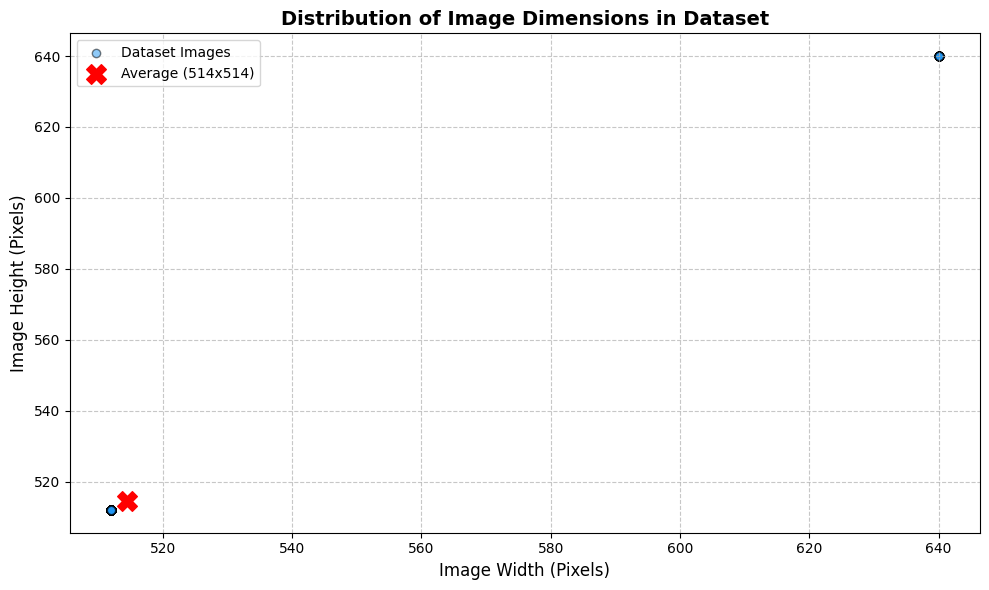

In [ ]:
# Cell 4: Exploratory Data Analysis (EDA) on Image Dimensions
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

print("--- Starting EDA on Image Dimensions ---")

# Explicitly mapping to your updated folder structure
DATASET_PATH = '/content/drive/MyDrive/Green_Apple/dataset/raw'
OUTPUT_PATH = '/content/drive/MyDrive/Green_Apple/dataset/outputs'

os.makedirs(OUTPUT_PATH, exist_ok=True)

if os.path.exists(DATASET_PATH):
    dimensions = [] # Store sizes as (width, height)

    # Strictly filtering out hidden system folders
    categories = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d)) and not d.startswith('.')])

    print("Analyzing image sizes across all categories...")

    for category in categories:
        category_path = os.path.join(DATASET_PATH, category)

        # Strictly filtering out hidden system files
        files = [f for f in os.listdir(category_path) if os.path.isfile(os.path.join(category_path, f)) and not f.startswith('.')]

        for filename in files:
            filepath = os.path.join(category_path, filename)
            try:
                # Open the image and get its (width, height)
                with Image.open(filepath) as img:
                    dimensions.append(img.size)
            except Exception as e:
                # Silently pass errors here since Cell 3 already handled corruptions
                pass

    if not dimensions:
        print("❌ Error: No valid images found to analyze.")
    else:
        # Separate widths and heights for math
        widths = [d[0] for d in dimensions]
        heights = [d[1] for d in dimensions]

        # Count the exact frequencies of each dimension tuple
        dim_counts = Counter(dimensions)

        avg_w, avg_h = np.mean(widths), np.mean(heights)
        med_w, med_h = np.median(widths), np.median(heights)
        min_w, min_h = np.min(widths), np.min(heights)
        max_w, max_h = np.max(widths), np.max(heights)

        print(f"\n📊 Image Dimension Statistics ({len(widths)} images):")
        print(f"  • Minimum Size: {min_w} x {min_h}")
        print(f"  • Maximum Size: {max_w} x {max_h}")
        print(f"  • Average Size: {avg_w:.0f} x {avg_h:.0f}")
        print(f"  • Median Size:  {med_w:.0f} x {med_h:.0f}\n")

        print("🔍 Exact Dimension Counts (Most Common First):")
        # Print the top 10 most common unique sizes to keep the output clean
        for (w, h), count in dim_counts.most_common(10):
            print(f"  • {w} x {h} pixels : {count} images")

        if len(dim_counts) > 10:
            print(f"  ... and {len(dim_counts) - 10} more unique sizes.")

        # Plotting the Scatter Plot
        plt.figure(figsize=(10, 6))
        plt.scatter(widths, heights, alpha=0.5, color='#2196F3', edgecolors='k', label='Dataset Images')
        plt.scatter(avg_w, avg_h, color='red', marker='X', s=200, label=f'Average ({avg_w:.0f}x{avg_h:.0f})')
        plt.title('Distribution of Image Dimensions in Dataset', fontsize=14, fontweight='bold')
        plt.xlabel('Image Width (Pixels)', fontsize=12)
        plt.ylabel('Image Height (Pixels)', fontsize=12)
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()

        # ---------------------------------------------------------
        # PROFESSIONAL ARTIFACT LOGGING
        # ---------------------------------------------------------
        save_file = os.path.join(OUTPUT_PATH, 'eda_image_dimensions.png')
        plt.savefig(save_file, dpi=300, bbox_inches='tight')
        print(f"\n✅ High-Resolution scatter plot saved to: {save_file}")

        # Display the plot in the Colab output
        plt.show()

else:
    print(f"❌ Error: Could not find '{DATASET_PATH}'. Please verify your Drive connection.")

In [ ]:
# Cell 5: Spatial Normalization (Aspect-Aware Resizing with Padding)
import os
from PIL import Image

print("--- Starting Aspect-Aware Spatial Normalization ---")

TARGET_SIZE = 512

# Explicitly mapping to your updated folder structure
DATASET_PATH = '/content/drive/MyDrive/Green_Apple/dataset/raw'

if os.path.exists(DATASET_PATH):
    resized_count = 0
    skipped_count = 0

    # Strictly filtering out hidden system folders
    categories = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d)) and not d.startswith('.')])

    for category in categories:
        category_path = os.path.join(DATASET_PATH, category)

        # Strictly filtering out hidden system files
        files = [f for f in os.listdir(category_path) if os.path.isfile(os.path.join(category_path, f)) and not f.startswith('.')]

        print(f"Normalizing '{category}' ({len(files)} images)...")

        for filename in files:
            filepath = os.path.join(category_path, filename)

            try:
                with Image.open(filepath) as img:
                    w, h = img.size

                    # If it's already 512x512, skip it to save time
                    if w == TARGET_SIZE and h == TARGET_SIZE:
                        skipped_count += 1
                        continue

                    # Calculate the ratio to shrink the longest side to 512
                    ratio = min(TARGET_SIZE / w, TARGET_SIZE / h)
                    new_w = int(w * ratio)
                    new_h = int(h * ratio)

                    # Resize the image using high-quality Lanczos algorithm
                    img_resized = img.resize((new_w, new_h), Image.Resampling.LANCZOS)

                    # Create a new, pure black 512x512 square image
                    new_img = Image.new("RGB", (TARGET_SIZE, TARGET_SIZE), (0, 0, 0))

                    # Paste the resized image right into the center of the black square
                    paste_x = (TARGET_SIZE - new_w) // 2
                    paste_y = (TARGET_SIZE - new_h) // 2
                    new_img.paste(img_resized, (paste_x, paste_y))

                    # Overwrite the original file with the perfectly padded square
                    new_img.save(filepath, format='JPEG')
                    resized_count += 1

            except Exception as e:
                print(f"  [ERROR] Processing {filename}: {e}")

    print(f"\n✅ Spatial Normalization Complete!")
    print(f"⏩ Skipped (Already Perfect): {skipped_count} images")
    print(f"🛠️ Padded & Resized: {resized_count} images")
    print("All images are now strictly 512x512 without geometric distortion.")

else:
    print(f"❌ Error: Could not find '{DATASET_PATH}'. Please verify your Drive connection.")

--- Starting Aspect-Aware Spatial Normalization ---
❌ Error: Could not find '/content/drive/MyDrive/Green_Apple/dataset/raw'. Please verify your Drive connection.


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split
from google.colab import drive

# 1. Mount your Google Drive to the Colab instance
drive.mount('/content/drive')

def split_drive_dataset(base_source, base_dest, classes, split_ratio=0.8):
    for class_name in classes:
        print(f"\n--- Processing Class: {class_name} ---")

        # Define exact paths for this specific class
        source_folder = os.path.join(base_source, class_name)
        train_folder = os.path.join(base_dest, "train", class_name)
        test_folder = os.path.join(base_dest, "val", class_name)

        # Create target directories
        os.makedirs(train_folder, exist_ok=True)
        os.makedirs(test_folder, exist_ok=True)

        # Grab all images
        if not os.path.exists(source_folder):
            print(f"Error: Could not find folder {source_folder}")
            continue

        all_files = os.listdir(source_folder)
        images = [f for f in all_files if f.endswith(('.jpg', '.png', '.jpeg'))]
        print(f"Found {len(images)} total images in {class_name}.")

        # Randomize and split
        train_images, test_images = train_test_split(images, train_size=split_ratio, random_state=42)

        def copy_files(image_list, destination):
            copied_count = 0
            skipped_count = 0

            for img_name in image_list:
                # 1. Handle Image Copy
                img_path = os.path.join(source_folder, img_name)
                dest_img_path = os.path.join(destination, img_name)

                # Only copy if it doesn't already exist
                if not os.path.exists(dest_img_path):
                    shutil.copy(img_path, destination)
                    copied_count += 1
                else:
                    skipped_count += 1

                # 2. Handle JSON Copy
                json_name = os.path.splitext(img_name)[0] + '.json'
                json_path = os.path.join(source_folder, json_name)
                dest_json_path = os.path.join(destination, json_name)

                if os.path.exists(json_path):
                    if not os.path.exists(dest_json_path):
                        shutil.copy(json_path, destination)

            return copied_count, skipped_count

        # Execute
        print("Copying to Train folder...")
        train_copied, train_skipped = copy_files(train_images, train_folder)
        print(f"  -> Copied: {train_copied} | Skipped (Already Exists): {train_skipped}")

        print("Copying to Test folder...")
        test_copied, test_skipped = copy_files(test_images, test_folder)
        print(f"  -> Copied: {test_copied} | Skipped (Already Exists): {test_skipped}")

# --- EXACT PATHS FOR YOUR GOOGLE DRIVE STRUCTURE ---
BASE_RAW_FOLDER = "/content/drive/MyDrive/Green_Apple/dataset/raw"
BASE_SPLIT_FOLDER = "/content/drive/MyDrive/Green_Apple/dataset/outputs/split"

# Just add any new folders to this list when you are ready for them
CLASSES_TO_PROCESS = ["Anthracnose", "Healthy", "Scab", "Blotch", "Black Rot"]

# Run the split for all classes in the list
split_drive_dataset(BASE_RAW_FOLDER, BASE_SPLIT_FOLDER, CLASSES_TO_PROCESS, split_ratio=0.8)

Mounted at /content/drive

--- Processing Class: Anthracnose ---
Found 295 total images in Anthracnose.
Copying to Train folder...
  -> Copied: 236 | Skipped (Already Exists): 0
Copying to Test folder...
  -> Copied: 59 | Skipped (Already Exists): 0

--- Processing Class: Healthy ---
Found 1424 total images in Healthy.
Copying to Train folder...
  -> Copied: 1139 | Skipped (Already Exists): 0
Copying to Test folder...
  -> Copied: 285 | Skipped (Already Exists): 0

--- Processing Class: Scab ---
Found 23 total images in Scab.
Copying to Train folder...
  -> Copied: 18 | Skipped (Already Exists): 0
Copying to Test folder...
  -> Copied: 5 | Skipped (Already Exists): 0

--- Processing Class: Blotch ---
Found 24 total images in Blotch.
Copying to Train folder...
  -> Copied: 19 | Skipped (Already Exists): 0
Copying to Test folder...
  -> Copied: 5 | Skipped (Already Exists): 0

--- Processing Class: Black Rot ---
Found 542 total images in Black Rot.
Copying to Train folder...
  -> Copied:

In [ ]:
import os
import json
import random
import cv2
import numpy as np
import albumentations as A
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# --- CONFIGURATION ---
BASE_TRAIN_DIR = "/content/drive/MyDrive/Green_Apple/dataset/outputs/split/train"
CLASSES_TO_AUGMENT = ["Anthracnose", "Scab", "Blotch"]
TARGET_TOTAL = 1139  # The exact number of your Healthy baseline

# 2. Define the Master Q1 Augmentation Pipeline
# remove_invisible=False is critical: it prevents the script from deleting points
# if a polygon stretches slightly off the edge of the rotated image.
transform = A.Compose([
    # Phase 1: Spatial & Geometry (Weird Angles)
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    # A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.2, rotate_limit=45, p=0.7, border_mode=cv2.BORDER_CONSTANT),
    # Change A.ShiftScaleRotate to A.Affine(For Blotch and Scab)
    A.Affine(translate_percent=0.0625, scale=(0.8, 1.2), rotate=(-45, 45), p=0.7, cval=0),

    # Phase 2: Photometric (Canopy Lighting)
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=0.3),

    # Phase 3: Sensor Noise & Blur (Cheap Phone Artifacts)
    A.OneOf([
        A.MotionBlur(blur_limit=5, p=1.0),
        A.GaussianBlur(blur_limit=5, p=1.0),
    ], p=0.3),
    # A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),

    # # Phase 4: Occlusion (Mud & Bugs)
    # A.CoarseDropout(max_holes=4, max_height=40, max_width=40, fill_value=0, p=0.15)
    # (For Blotch and Scab)
    # Fix the GaussNoise and CoarseDropout syntax
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.2), # This is fine in the latest version, but ensure albumentations is updated
    # Change CoarseDropout to avoid the warning (some older args were deprecated)
    A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(10, 40), hole_width_range=(10, 40), fill_value=0, p=0.15)
], keypoint_params=A.KeypointParams(format='xy', remove_invisible=False))


def process_and_augment(class_name):
    # # Grab ONLY the original images (ignoring ones that already have '_aug_' in the name)
    # all_files = os.listdir(TRAIN_FOLDER)
    # (For Blotch and Scab)
    print(f"\n========== AUGMENTING: {class_name} ==========")
    TRAIN_FOLDER = os.path.join(BASE_TRAIN_DIR, class_name)

    if not os.path.exists(TRAIN_FOLDER):
        print(f"Error: {TRAIN_FOLDER} not found.")
        return

    all_files = os.listdir(TRAIN_FOLDER)

    original_images = [f for f in all_files if f.endswith(('.jpg', '.png')) and '_aug_' not in f]

    # Calculate exactly how many we need to generate to reach 1139
    current_total = len([f for f in all_files if f.endswith(('.jpg', '.png'))])
    needed = TARGET_TOTAL - current_total

    if needed <= 0:
        print(f"Folder already has {current_total} images. No augmentation needed!")
        return

    print(f"Found {len(original_images)} pristine original images.")
    print(f"Target is {TARGET_TOTAL}. Generating {needed} unique augmented copies...\n")

    for i in range(needed):
        # Randomly pick an original image to act as the base
        base_img_name = random.choice(original_images)
        base_name = os.path.splitext(base_img_name)[0]

        img_path = os.path.join(TRAIN_FOLDER, base_img_name)
        json_path = os.path.join(TRAIN_FOLDER, base_name + '.json')

        if not os.path.exists(json_path):
            continue # Skip if JSON is somehow missing

        # A. Read Image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Albumentations uses RGB

        # B. Read JSON & Extract Polygon Coordinates
        with open(json_path, 'r') as f:
            data = json.load(f)

        keypoints = []
        shape_lengths = []
        for shape in data['shapes']:
            pts = shape['points']
            shape_lengths.append(len(pts)) # Remember how many points this specific polygon has
            keypoints.extend(pts) # Throw them all into one massive list for the math engine

        # C. EXECUTE THE SLOT MACHINE MATH
        transformed = transform(image=image, keypoints=keypoints)
        aug_img = transformed['image']
        aug_kps = transformed['keypoints']

        # D. Reconstruct the JSON with the new Math
        new_data = data.copy()
        new_data['imagePath'] = f"{base_name}_aug_{i}.jpg"
        new_data['imageData'] = None # Forces labeling software to read from the new file, not cache

        idx = 0
        for s_idx, length in enumerate(shape_lengths):
            # Put the newly calculated coordinates back into their correct polygons
            new_data['shapes'][s_idx]['points'] = aug_kps[idx : idx + length]
            idx += length

        # E. Save the new Augmented Image
        aug_img_name = f"{base_name}_aug_{i}.jpg"
        aug_img_path = os.path.join(TRAIN_FOLDER, aug_img_name)
        cv2.imwrite(aug_img_path, cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

        # F. Save the new Augmented JSON
        aug_json_name = f"{base_name}_aug_{i}.json"
        aug_json_path = os.path.join(TRAIN_FOLDER, aug_json_name)
        with open(aug_json_path, 'w') as f:
            json.dump(new_data, f, indent=2)

        # Print progress every 100 images
        if (i + 1) % 100 == 0:
            print(f"Generated {i + 1} / {needed} images...")

    print(f"\nSUCCESS! Folder now contains exactly {TARGET_TOTAL} highly robust images.")

# Run the pipeline for all classes in your list
for class_name in CLASSES_TO_AUGMENT:
    process_and_augment(class_name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

========== AUGMENTING: Anthracnose ==========
Found 236 pristine original images.
Target is 1139. Generating 903 unique augmented copies...



/tmp/ipykernel_318/3369987822.py:26: UserWarning: Argument(s) 'cval' are not valid for transform Affine
  A.Affine(translate_percent=0.0625, scale=(0.8, 1.2), rotate=(-45, 45), p=0.7, cval=0),
/tmp/ipykernel_318/3369987822.py:43: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.2), # This is fine in the latest version, but ensure albumentations is updated
/tmp/ipykernel_318/3369987822.py:45: UserWarning: Argument(s) 'fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(10, 40), hole_width_range=(10, 40), fill_value=0, p=0.15)


Generated 100 / 903 images...
Generated 200 / 903 images...
Generated 300 / 903 images...
Generated 400 / 903 images...
Generated 500 / 903 images...
Generated 600 / 903 images...
Generated 700 / 903 images...
Generated 800 / 903 images...
Generated 900 / 903 images...

SUCCESS! Folder now contains exactly 1139 highly robust images.

========== AUGMENTING: Scab ==========
Found 18 pristine original images.
Target is 1139. Generating 1121 unique augmented copies...

Generated 100 / 1121 images...
Generated 200 / 1121 images...
Generated 300 / 1121 images...
Generated 400 / 1121 images...
Generated 500 / 1121 images...
Generated 600 / 1121 images...
Generated 700 / 1121 images...
Generated 800 / 1121 images...
Generated 900 / 1121 images...
Generated 1000 / 1121 images...
Generated 1100 / 1121 images...

SUCCESS! Folder now contains exactly 1139 highly robust images.

========== AUGMENTING: Blotch ==========
Found 19 pristine original images.
Target is 1139. Generating 1120 unique augmen

In [ ]:
# CELL 1: PREPARE CLEAN YOLO DATASET
import os
import shutil
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/Green_Apple/dataset/outputs/split"
# We create a specific clean directory for YOLO
YOLO_CLEAN_DIR = "/content/drive/MyDrive/Green_Apple/dataset/outputs/yolo_clean_v3"

print("Creating pristine data environment for YOLO...")

for split in ['train', 'val']:
    split_src = os.path.join(BASE_DIR, split)
    split_dst = os.path.join(YOLO_CLEAN_DIR, split)

    if not os.path.exists(split_src):
        continue

    for class_name in os.listdir(split_src):
        class_src = os.path.join(split_src, class_name)
        class_dst = os.path.join(split_dst, class_name)
        os.makedirs(class_dst, exist_ok=True)

        # ONLY copy the original images (ignore the old _aug_ files)
        count = 0
        for f in os.listdir(class_src):
            if f.endswith(('.jpg', '.png')) and '_aug_' not in f:
                shutil.copy2(os.path.join(class_src, f), os.path.join(class_dst, f))
                count += 1
        print(f"Copied {count} pristine images for {split}/{class_name}")

print(f"\n✅ Clean YOLO dataset ready at: {YOLO_CLEAN_DIR}")

Mounted at /content/drive
Creating pristine data environment for YOLO...
Copied 236 pristine images for train/Anthracnose
Copied 1139 pristine images for train/Healthy
Copied 18 pristine images for train/Scab
Copied 19 pristine images for train/Blotch
Copied 433 pristine images for train/Black Rot
Copied 59 pristine images for val/Anthracnose
Copied 285 pristine images for val/Healthy
Copied 5 pristine images for val/Scab
Copied 5 pristine images for val/Blotch
Copied 109 pristine images for val/Black Rot

✅ Clean YOLO dataset ready at: /content/drive/MyDrive/Green_Apple/dataset/outputs/yolo_clean_v3
